<a href="https://colab.research.google.com/github/Anshu-Tomar/CapstoneProject-Beyond-Predictive-Accuracy/blob/data-eda/DataEDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/Anshu-Tomar/CapstoneProject-Beyond-Predictive-Accuracy.git

Cloning into 'CapstoneProject-Beyond-Predictive-Accuracy'...
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 19 (delta 7), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (19/19), 34.22 KiB | 8.56 MiB/s, done.
Resolving deltas: 100% (7/7), done.


In [2]:
%cd /content/CapstoneProject-Beyond-Predictive-Accuracy

/content/CapstoneProject-Beyond-Predictive-Accuracy


In [4]:
!git branch

* data-eda
  main


In [3]:
!git checkout data-eda

branch 'data-eda' set up to track 'origin/data-eda'.
Switched to a new branch 'data-eda'




```
# **Step**
1	Load data	--------------->Done
2	Data validation	--------------->Done
3	Data cleaning	--------------->Done
4	EDA (Exploratory Data Analysis)	--------------->Done
5	Preprocessing (encoding, train/test split)	-----------> Done
6	Baseline model
7	Handle imbalance and train the models
8	Evaluate (not only accuracy)
9	Explain the model and conclusion
```



In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb

df = pd.read_excel('/content/CapstoneProject-Beyond-Predictive-Accuracy/Diabetes Simple Diagnosis.csv.xlsx')
df.head()

,Unnamed: 0,Age,Gender,BMI,High_BP,FBS,HbA1c_level,Smoking,Diagnosis
0,0,80,Female,25,0,140,6.6,0,0
1,1,54,Female,27,0,80,6.6,0,0
2,2,28,Male,27,0,158,5.7,0,0
3,3,36,Female,23,0,155,5.0,1,0
4,4,76,Male,20,1,155,4.8,1,0


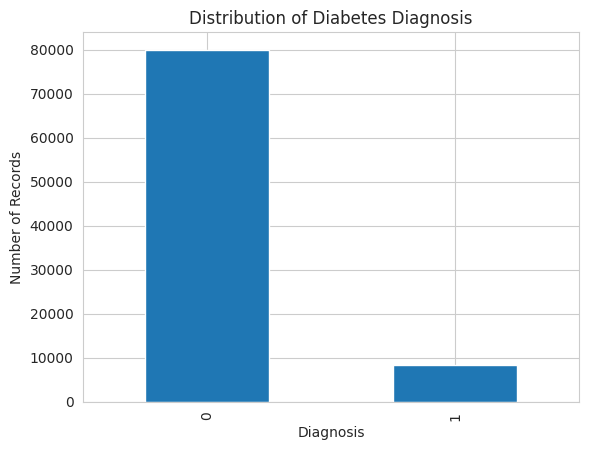

In [22]:
df['Diagnosis'].value_counts().plot(
    kind='bar',
    title='Distribution of Diabetes Diagnosis'
)
plt.xlabel('Diagnosis')
plt.ylabel('Number of Records')
plt.show()

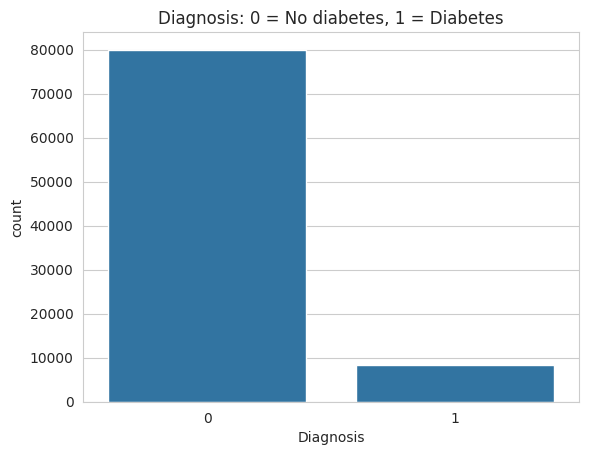

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
sns.countplot(x='Diagnosis', data=df)
plt.title("Diagnosis: 0 = No diabetes, 1 = Diabetes")
plt.show()

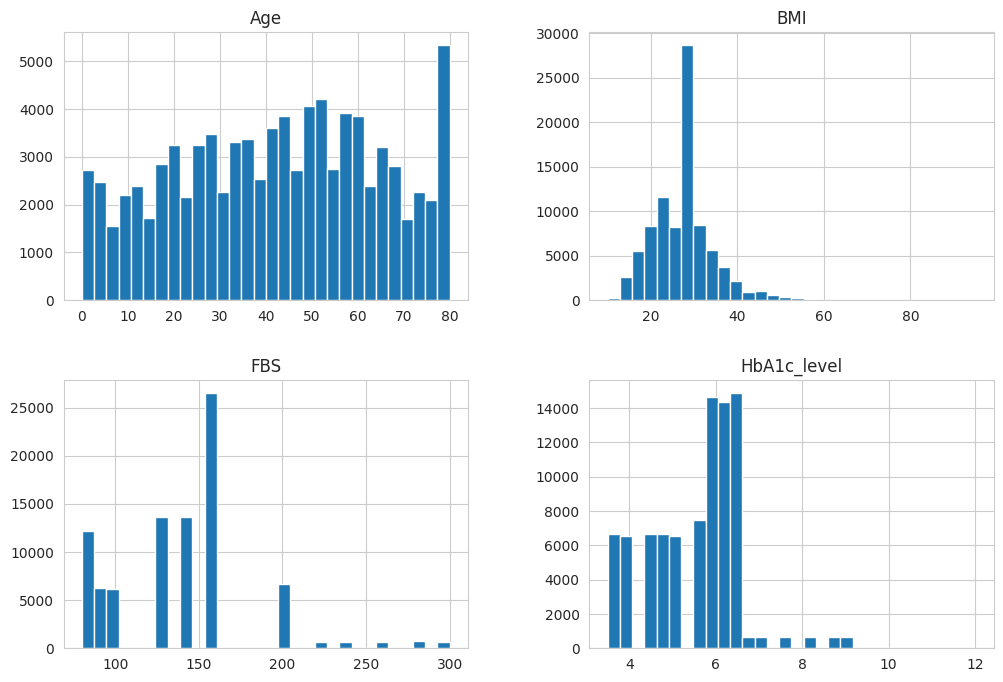

In [28]:
num_cols = ['Age', 'BMI', 'FBS', 'HbA1c_level']
df[num_cols].hist(bins=30, figsize=(12, 8))
plt.show()

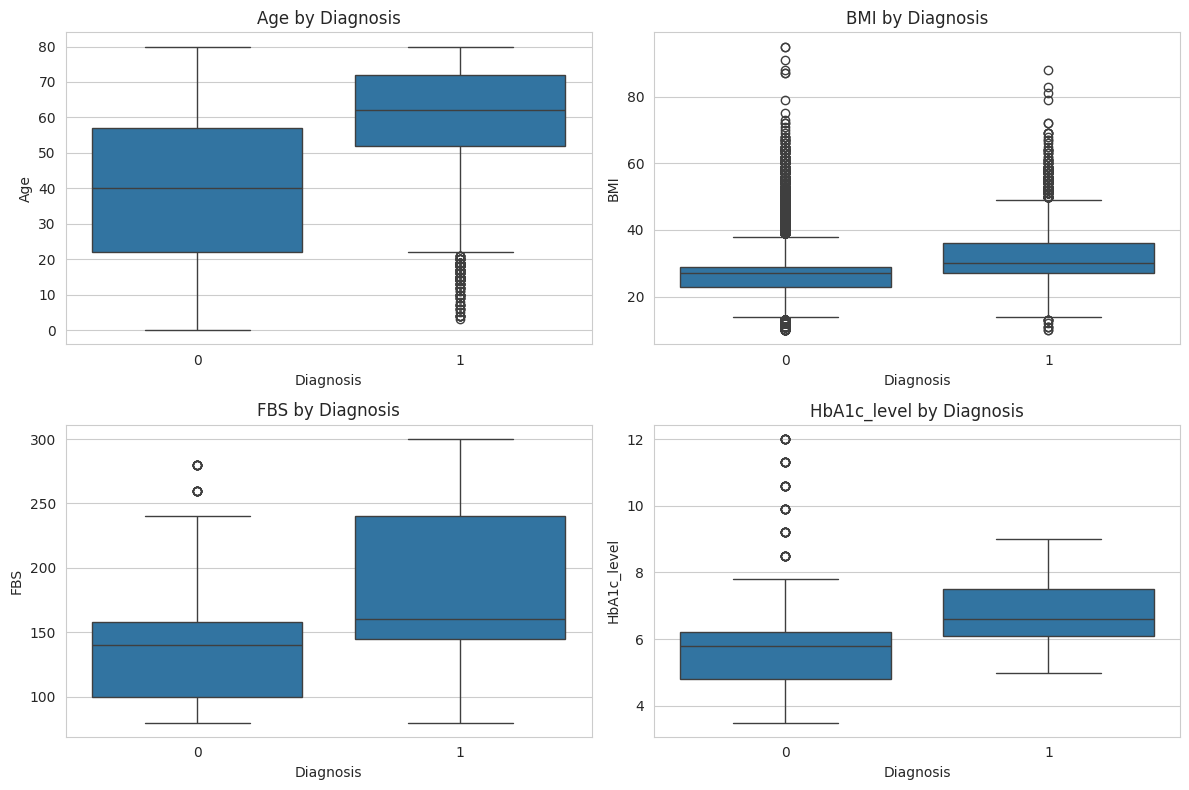

In [29]:
#Compare diabetic and non-diabetic people (boxplots)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x='Diagnosis', y=col, data=df, ax=ax)
    ax.set_title(f"{col} by Diagnosis")
plt.tight_layout()
plt.show()

In [30]:
#Diabetes rate by category

for col in ['Gender', 'High_BP', 'Smoking']:
    rate = df.groupby(col)['Diagnosis'].mean() * 100
    print(f"\nDiabetes rate (%) by {col}:")
    print(rate.round(2))


Diabetes rate (%) by Gender:
Gender
0     8.59
1    10.84
2     0.00
Name: Diagnosis, dtype: float64

Diabetes rate (%) by High_BP:
High_BP
0     7.83
1    28.08
Name: Diagnosis, dtype: float64

Diabetes rate (%) by Smoking:
Smoking
0     7.77
1    13.40
Name: Diagnosis, dtype: float64


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88380 entries, 0 to 88379
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          88380 non-null  int64  
 1   Gender       88380 non-null  int64  
 2   BMI          88380 non-null  int64  
 3   High_BP      88380 non-null  int64  
 4   FBS          88380 non-null  int64  
 5   HbA1c_level  88380 non-null  float64
 6   Smoking      88380 non-null  int64  
 7   Diagnosis    88380 non-null  int64  
dtypes: float64(1), int64(7)
memory usage: 5.4 MB


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
X = df[['Age', 'Gender', 'BMI', 'High_BP',
        'FBS', 'HbA1c_level', 'Smoking']]

y = df['Diagnosis']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numerical_features = [
    'Age', 'BMI', 'FBS', 'HbA1c_level'
]

categorical_features = [
    'Gender', 'High_BP', 'Smoking'
]
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])
print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

print("Training diagnosis:")
print(y_train.value_counts())

print("Testing diagnosis:")
print(y_test.value_counts())

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Training records: (70704, 7)
Testing records: (17676, 7)
Training diagnosis:
Diagnosis
0    63965
1     6739
Name: count, dtype: int64
Testing diagnosis:
Diagnosis
0    15991
1     1685
Name: count, dtype: int64
Processed training shape: (70704, 11)
Processed testing shape: (17676, 11)


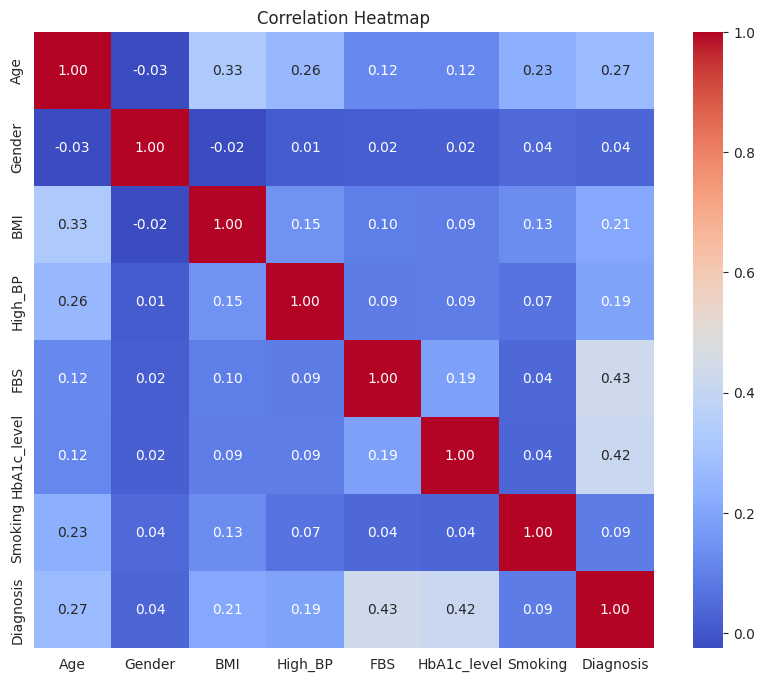

AttributeError: 'list' object has no attribute 'fit_transform'

In [35]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Basic EDA
# Drop unnecessary identifier column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Correlation Heatmap for numerical values
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()
numerical_features = [
    'Age', 'BMI', 'FBS', 'HbA1c_level'
]

categorical_features = [
    'Gender', 'High_BP', 'Smoking'
]

# 2. Preprocessing
# Encode categorical variables (Gender)
le = numerical_features;
if 'Gender' in df.columns:
    df['Gender'] = le(df['Gender'])
    print("\nGender Encoded successfully. Classes:", le.classes_)

# Define features (X) and target (y)
X = df.drop(columns=['Diagnosis'])
y = df['Diagnosis']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nPreprocessing complete!")
print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     15991
           1       0.91      0.67      0.77      1685

    accuracy                           0.96     17676
   macro avg       0.94      0.83      0.88     17676
weighted avg       0.96      0.96      0.96     17676



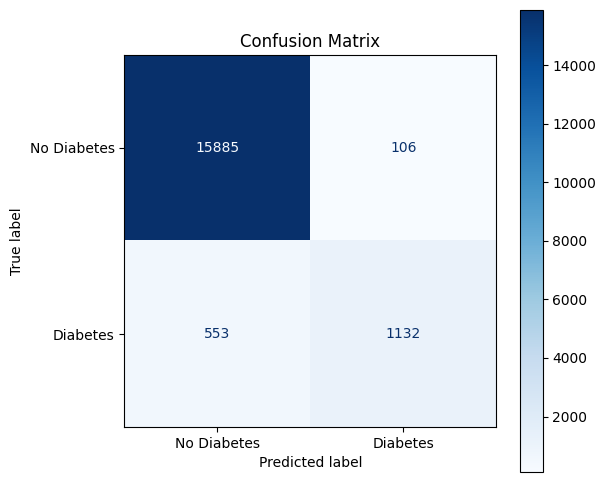

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize and train the classifier
model = RandomForestClassifier(random_state=42, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# 1. Classification Report
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
plt.show()